In [10]:
using Plots

f(x) = x^2-3*x+1

a = 1.0
b = 3.0
eps = 1e-6
x0 = (a + b)/2
tau = 0.07

x_plot = range(a, b, length=400)

1.0:0.005012531328320802:3.0

In [11]:
function bisection(a, b)
    if f(a)*f(b) >= 0
        error("На концах интервала функция должна иметь разные знаки")
    end
    history = []
    n = 0
    while (b - a)/2 > eps
        c = (a + b)/2
        push!(history, (a, b, c))
        n = n + 1
        if f(c) == 0
            return c, n, history
        elseif f(a)*f(c) < 0
            b = c
        else
            a = c
        end
    end
    return (a + b)/2, n, history
end

r1, n1, h1 = bisection(a, b)
println("Метод секущих:")
println("Корень: ", round(r1, digits=9))
println("Количество итераций: ", n1)

Метод секущих:
Корень: 2.618033409
Количество итераций: 20


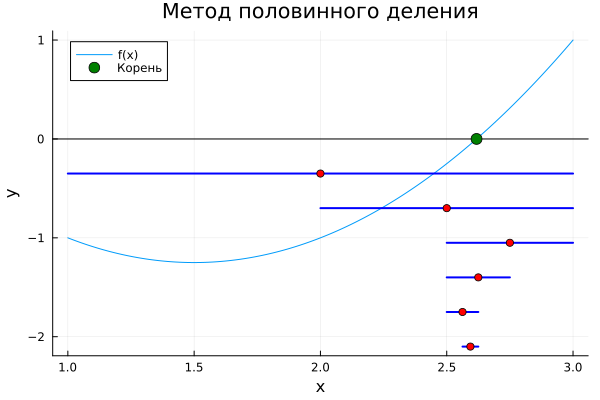

In [12]:
p = plot(x_plot, f.(x_plot), label="f(x)", xlabel="x", ylabel="y", title="Метод половинного деления")
hline!(p, [0], color=:black, label="")

for i in 1:min(n1, 6)
    left, right, middle = h1[i]
    y = -0.35*i
    plot!(p, [left, right], [y, y], color=:blue, linewidth=2, label="")
    scatter!(p, [middle], [y], color=:red, markersize=4, label="")
end

scatter!(p, [r1], [0], color=:green, markersize=6, label="Корень")
display(p)

In [13]:
function relaxation(x0, tau)
    history = [x0]
    n = 0
    while abs(f(x0)) > eps
        x0 = x0 - tau*f(x0)
        push!(history, x0)
        n = n + 1
    end
    return x0, n, history
end

r2, n2, h2 = relaxation(x0, tau)
println("Метод секущих:")
println("Корень: ", round(r2, digits=9))
println("Количество итераций: ", n2)

Метод секущих:
Корень: 2.618033591
Количество итераций: 86


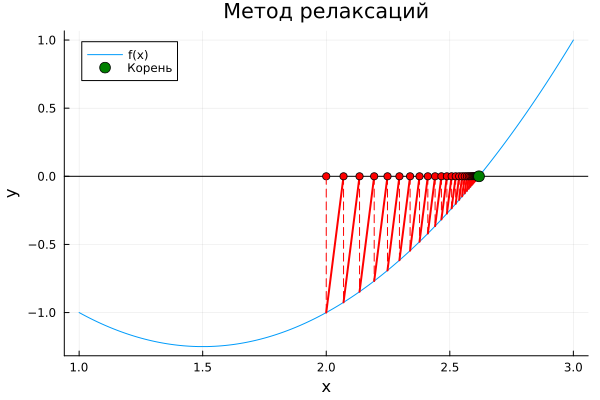

In [14]:
p = plot(x_plot, f.(x_plot), label="f(x)", xlabel="x", ylabel="y", title="Метод релаксаций")
hline!(p, [0], color=:black, label="")
scatter!(p, [h2[1]], [0], color=:red, markersize=4, label="")
plot!(p, [h2[1], h2[1]], [0, f(h2[1])], color=:red, linestyle=:dash, label="")

for i in 1:n2
    x = h2[i]
    x_new = h2[i+1]
    plot!(p, [x, x_new], [f(x), 0], color=:red, linewidth=2, label="")
    plot!(p, [x_new, x_new], [0, f(x_new)], color=:red, linestyle=:dash, label="")
    scatter!(p, [x_new], [0], color=:red, markersize=4, label="")
end

scatter!(p, [r2], [0], color=:green, markersize=6, label="Корень")
display(p)

In [15]:
function secant(x0, x1)
    history = [x0, x1]
    n = 0
    while abs(f(x1)) > eps
        x_new = x1 - f(x1)*(x1 - x0)/(f(x1) - f(x0))
        push!(history, x_new)
        x0 = x1
        x1 = x_new
        n = n + 1
    end
    return x1, n, history
end

r3, n3, h3 = secant(a, b)
println("Метод секущих:")
println("Корень: ", round(r3, digits=9))
println("Количество итераций: ", n3)

Метод секущих:
Корень: 2.618034056
Количество итераций: 6


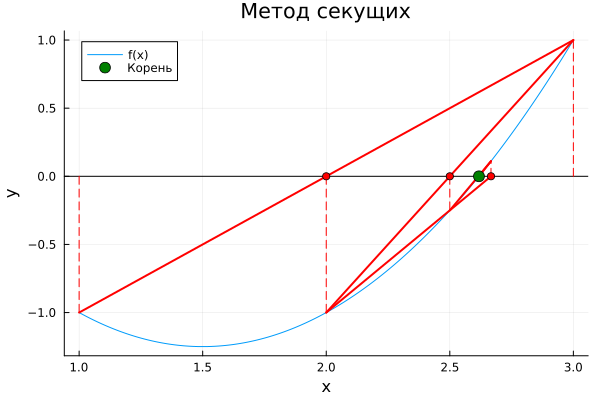

In [16]:
p = plot(x_plot, f.(x_plot), label="f(x)", xlabel="x", ylabel="y", title="Метод секущих")
hline!(p, [0], color=:black, label="")
plot!(p, [a, a], [0, f(a)], color=:red, linestyle=:dash, label="")
plot!(p, [b, b], [0, f(b)], color=:red, linestyle=:dash, label="")

for i in 1:min(n3, 5)
    x_old = h3[i]
    x = h3[i+1]
    x_new = h3[i+2]
    plot!(p, [x_old, x, x_new], [f(x_old), f(x), 0], color=:red, linewidth=2, label="")
    plot!(p, [x_new, x_new], [0, f(x_new)], color=:red, linestyle=:dash, label="")
    scatter!(p, [x_new], [0], color=:red, markersize=4, label="")
end

scatter!(p, [r3], [0], color=:green, markersize=6, label="Корень")
display(p)

In [17]:
x_exact = 2.618033988

names = ["Метод половинного деления", "Метод релаксаций", "Метод секущих"]
roots = [r1, r2, r3]
iterations = [n1, n2, n3]

println("Численное значение точного решения: ", x_exact)
println()

println("Точность:")
for i in 1:3
    println(names[i])
    println("Корень: ", roots[i])
    println("Точность: ", abs(x_exact - roots[i]))
    println()
end

println("Количество итераций:")
for i in 1:3
    println(names[i], ": ", iterations[i])
end

Численное значение точного решения: 2.618033988

Точность:
Метод половинного деления
Корень: 2.6180334091186523
Точность: 5.788813477458632e-7

Метод релаксаций
Корень: 2.6180335911572863
Точность: 3.968427138012487e-7

Метод секущих
Корень: 2.618034055727554
Точность: 6.772755378747775e-8

Количество итераций:
Метод половинного деления: 20
Метод релаксаций: 86
Метод секущих: 6
